<a href="https://colab.research.google.com/github/cromeron/DemoGit/blob/main/EDA_CONTAINERS_MAZATLAN_H12025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

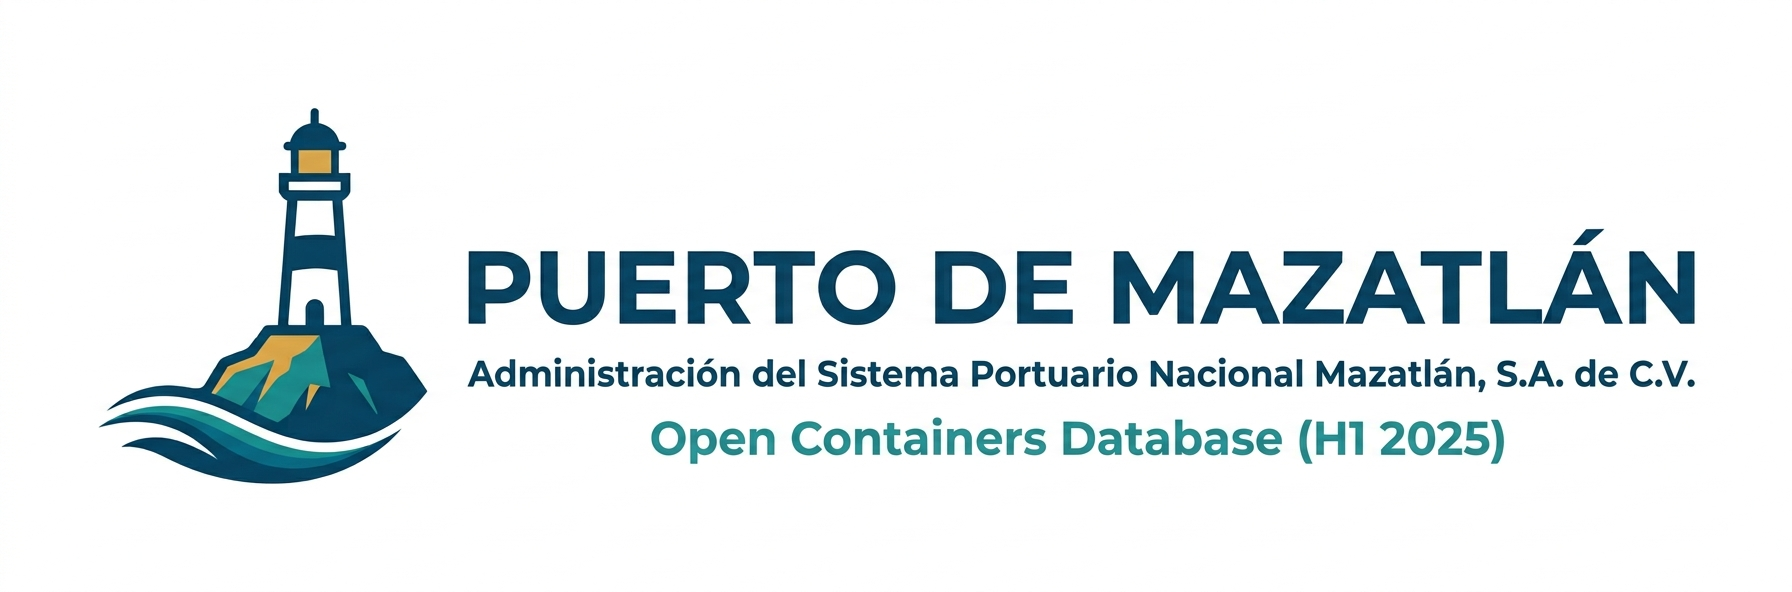



**1. EXPLORAR DATOS**: *Entender la estructura, variables, tipos y alcance del dataset*

In [758]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


df = pd.read_csv('ContenedoresENEJUN2025.csv')
df.head(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio
0,llenos,altura,importacion,10 pies,NaN,NaN,NaN,NaN,enero,2025
1,llenos,altura,importacion,20 pies,NaN,140.0,2982.104569,308.0,enero,2025
2,llenos,altura,importacion,40 pies,107.0,728.0,17786.123681,3674.0,enero,2025
3,llenos,altura,importacion,45 pies,NaN,NaN,NaN,NaN,enero,2025
4,llenos,altura,importacion,53 pies,NaN,NaN,NaN,NaN,enero,2025


In [759]:
df.tail(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio
355,vacios,transbordo,salida,10 pies,NaN,NaN,NaN,NaN,junio,2025
356,vacios,transbordo,salida,20 pies,NaN,NaN,NaN,NaN,junio,2025
357,vacios,transbordo,salida,40 pies,NaN,NaN,NaN,NaN,junio,2025
358,vacios,transbordo,salida,45 pies,NaN,NaN,NaN,NaN,junio,2025
359,vacios,transbordo,salida,53 pies,NaN,NaN,NaN,NaN,junio,2025




1.  Columna "***ll_vc***" : Separa la carga comercial de contenedores (Llenos) del movimiento de equipo logístico de contenedores (Vacíos).
2.  Columna "***navegacion***": Define el ámbito geográfico del barco, es decir el tipo de ruta de navegacion del contenedor: Altura, Cabotaje y Transbordo.
3.  Columna "***trafico***": Importación/Exportación o Entrada/Salida.
4.  Columna "***tamanio***": Son las dimensiones físicas del contenedor en pies.
5.  Columna "***refrig***": Representa el conteo de contenedores refrigerados.
6.  Columna "***otros***": Representa el conteo de contenedores de carga seca general u otros tipos.
7.  Columna "***carga***": Es el peso neto en kg de las mercancías que van dentro de los contenedores.
8.  Columna "***tara***": Es el peso en kg propio de los contenedores vacíos.
9.  Columna "***mes***": Periodo del mes de enero al mes de junio de 2025.
10. Columna "***anio***": Es el año de recopilación de datos 2025.









In [760]:
df.columns  # nombre de columnas

Index(['ll_vc', 'navegacion', 'trafico', 'tamanio', 'refrig', 'otros', 'carga',
       'tara', 'mes', 'anio'],
      dtype='object')

In [761]:
df.shape    # filas y columnas
df.info()   # Tipos y datos nulos

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 360 entries, 0 to 359
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ll_vc       360 non-null    object 
 1   navegacion  360 non-null    object 
 2   trafico     360 non-null    object 
 3   tamanio     360 non-null    object 
 4   refrig      19 non-null     float64
 5   otros       40 non-null     float64
 6   carga       24 non-null     float64
 7   tara        43 non-null     float64
 8   mes         360 non-null    object 
 9   anio        360 non-null    int64  
dtypes: float64(4), int64(1), object(5)
memory usage: 28.3+ KB


**2. PERFILAR CALIDAD**: *Detectar valores perdidos o faltantes, duplicados, atípicos y categorias inusuales*


In [762]:
df.isna().sum() #nulos por columna

,0
ll_vc,0
navegacion,0
trafico,0
tamanio,0
refrig,341
otros,320
carga,336
tara,317
mes,0
anio,0


In [763]:
df.duplicated().sum() #filas repetidas

np.int64(0)

In [764]:
df["ll_vc"].value_counts()

,count
ll_vc,
llenos,180
vacios,180


In [765]:
df["navegacion"].value_counts()

,count
navegacion,
altura,120
cabotaje,120
transbordo,120


In [766]:
df["trafico"].value_counts()

,count
trafico,
salida,120
entrada,120
exportacion,60
importacion,60


In [767]:
df["tamanio"].value_counts()

,count
tamanio,
10 pies,72
20 pies,72
40 pies,72
45 pies,72
53 pies,72


**2.1 Filtrar y ordenar información**

In [768]:
df_limpieza = df.copy()
df_limpieza.shape    # filas y columnas

(360, 10)

**2.1.1 Eliminar registros duplicados**

In [769]:
# Eliminar resgistros duplicados
df_limpieza = df_limpieza.drop_duplicates()
print(f"Dimensiones despues de remover duplicados: {df_limpieza.shape}")

Dimensiones despues de remover duplicados: (360, 10)


**2.1.2 Imputación de valores nulos**

In [770]:
# Calcular valor de reemplazo en valores nulos de contenedores vacios
# Si el contendor esta vacio el valor de las columnas carga, refri y otro es 0.
es_vacio = df_limpieza['ll_vc'] == 'vacios'
df_limpieza.loc[es_vacio, 'carga'] = df_limpieza.loc[es_vacio, 'carga'].fillna(0)
df_limpieza.loc[es_vacio, 'refrig'] = df_limpieza.loc[es_vacio, 'refrig'].fillna(0)
df_limpieza.loc[es_vacio, 'otros'] = df_limpieza.loc[es_vacio, 'otros'].fillna(0)
df_limpieza.loc[es_vacio, 'tara'] = df_limpieza.loc[es_vacio, 'tara'].fillna(0)

# Calcular valor de reemplazo en valores nulos de contenedores vacios
# Si el contendor esta vacio el valor de las columnas carga, refri y otro es 0.
es_lleno = df_limpieza['ll_vc'] == 'llenos'
df_limpieza.loc[es_lleno, 'carga'] = df_limpieza.loc[es_lleno, 'carga'].fillna(0)
df_limpieza.loc[es_lleno, 'refrig'] = df_limpieza.loc[es_lleno, 'refrig'].fillna(0)
df_limpieza.loc[es_lleno, 'otros'] = df_limpieza.loc[es_lleno, 'otros'].fillna(0)
df_limpieza.loc[es_lleno, 'tara'] = df_limpieza.loc[es_lleno, 'tara'].fillna(0)

# Agregar columna fecha
meses_num = {
    'enero': 1, 'febrero': 2, 'marzo': 3, 'abril': 4,
    'mayo': 5, 'junio': 6, 'julio': 7, 'agosto': 8,
    'septiembre': 9, 'octubre': 10, 'noviembre': 11, 'diciembre': 12
}

# Agregar una columna con el número de mes
df_limpieza['mes_num'] = df['mes'].map(meses_num)


In [771]:
df_limpieza.head(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio,mes_num
0,llenos,altura,importacion,10 pies,0.0,0.0,0.000000,0.0,enero,2025,1
1,llenos,altura,importacion,20 pies,0.0,140.0,2982.104569,308.0,enero,2025,1
2,llenos,altura,importacion,40 pies,107.0,728.0,17786.123681,3674.0,enero,2025,1
3,llenos,altura,importacion,45 pies,0.0,0.0,0.000000,0.0,enero,2025,1
4,llenos,altura,importacion,53 pies,0.0,0.0,0.000000,0.0,enero,2025,1


**2.1.3 Detectar inconsistencias en registros**

In [772]:
from numpy._core.umath import NAN
# Buscar "Contenedores llenos" que tengan 0 toneladas de carga (error de captura)
llenos_sin_carga = df_limpieza[(df_limpieza['ll_vc'] == 'llenos') & (df_limpieza['carga'] == 0.000000)]

# Buscar "Contenedores vacíos" que tengan toneladas de carga registradas (error de captura)
vacios_con_carga = df_limpieza[(df_limpieza['ll_vc'] == 'vacios') & (df_limpieza['carga'] > 0)]

print(f"Inconsistencias 'Llenos sin carga': {len(llenos_sin_carga)}")
print(f"Inconsistencias 'Vacíos con carga': {len(vacios_con_carga)}")

Inconsistencias 'Llenos sin carga': 156
Inconsistencias 'Vacíos con carga': 0


**2.1.4 Obtener dataset útil para eliminar ruido en el análisis.**

In [773]:
# Obtenemos el dataset con valores utiles para el analisis
columnas_metricas = ['carga']
condicion_ceros = (df_limpieza[columnas_metricas] == 0).all(axis=1)
condicion_llenos = (df_limpieza['ll_vc'] == 'llenos')

# Con ~ invertimos la selección para conservar todo lo que NO cumpla ambas condiciones
df_util = df_limpieza[~(condicion_ceros & condicion_llenos)].copy().sort_values(by='mes_num', ascending=True)

df_util.shape    # filas y columnas equivalentes al 11.94% de registros reales

(204, 11)

In [774]:
df_util.head(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio,mes_num
1,llenos,altura,importacion,20 pies,0.0,140.0,2982.104569,308.0,enero,2025,1
2,llenos,altura,importacion,40 pies,107.0,728.0,17786.123681,3674.0,enero,2025,1
6,llenos,altura,exportacion,20 pies,0.0,226.0,5468.814423,497.2,enero,2025,1
7,llenos,altura,exportacion,40 pies,54.0,231.0,6896.513763,1254.0,enero,2025,1
30,vacios,altura,importacion,10 pies,0.0,0.0,0.000000,0.0,enero,2025,1


**2.1.5 Segmentacion de dataset útil con estatus de carga vacia.**

In [775]:
df_util_vacios = df_util[(df_util['ll_vc'] == 'vacios')].copy()
df_util_vacios.shape    # filas y columnas

(180, 11)

In [776]:
df_util_vacios.head(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio,mes_num
30,vacios,altura,importacion,10 pies,0.0,0.0,0.0,0.0,enero,2025,1
31,vacios,altura,importacion,20 pies,0.0,50.0,0.0,110.0,enero,2025,1
32,vacios,altura,importacion,40 pies,15.0,0.0,0.0,66.0,enero,2025,1
33,vacios,altura,importacion,45 pies,0.0,0.0,0.0,0.0,enero,2025,1
34,vacios,altura,importacion,53 pies,0.0,0.0,0.0,0.0,enero,2025,1


**2.1.6 Segmentacion de dataset útil con estatus de carga llena.**

In [777]:
df_util_carga = df_util[(df_util['ll_vc'] == 'llenos')].copy()
df_util_carga.shape    # filas y columnas

(24, 11)

In [778]:
df_util_carga.head(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio,mes_num
1,llenos,altura,importacion,20 pies,0.0,140.0,2982.104569,308.0,enero,2025,1
2,llenos,altura,importacion,40 pies,107.0,728.0,17786.123681,3674.0,enero,2025,1
6,llenos,altura,exportacion,20 pies,0.0,226.0,5468.814423,497.2,enero,2025,1
7,llenos,altura,exportacion,40 pies,54.0,231.0,6896.513763,1254.0,enero,2025,1
61,llenos,altura,importacion,20 pies,0.0,82.0,1708.986685,180.4,febrero,2025,2


**Valores de la columna carga dentro del límite**


**2.1.7 Análisis de valores del dataset útil con estatus de carga llena.**

In [779]:
#df_util_carga["carga"].describe()

Valores de la columna carga en registros con estatus de carga llena dentro de los limites.

<Axes: >

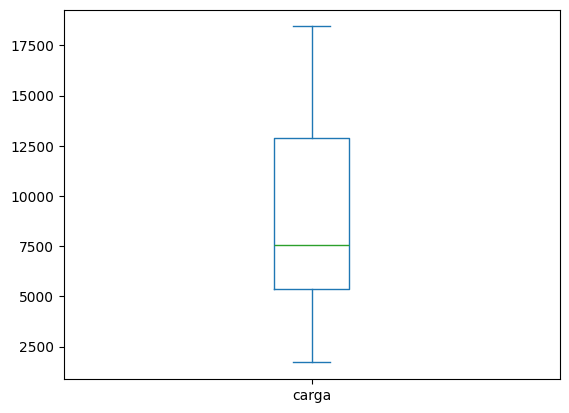

In [780]:
df_util_carga["carga"].plot.box()

In [781]:
#df_util_carga["tara"].describe()

Valores de la columna tara en registros con estatus de carga llena fuera de los limites.:

<Axes: >

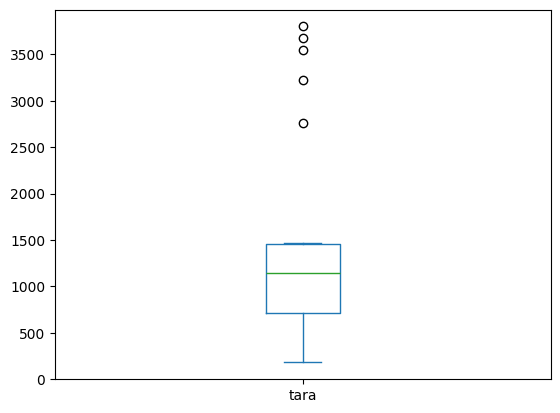

In [782]:
df_util_carga["tara"].plot.box()

Analizar los valores atípicos o outliers detectados en los valores de la columna tara en registros con estatus de carga llena.

In [783]:
# Calcular cuartiles y rango intercuartílico (IQR) para la columna 'tara'
Q1 = df_util_carga["tara"].quantile(0.25)
Q3 = df_util_carga["tara"].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Filtrar los registros atípicos
outliers_tara = df_util_carga[df_util_carga["tara"] > limite_superior]

print(f"Límite superior estadístico: {limite_superior:.2f} kg")
print(f"Cantidad de outliers detectados: {len(outliers_tara)}")
display(outliers_tara)

Límite superior estadístico: 2563.00 kg
Cantidad de outliers detectados: 5


,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio,mes_num
2,llenos,altura,importacion,40 pies,107.0,728.0,17786.123681,3674.0,enero,2025,1
62,llenos,altura,importacion,40 pies,47.0,759.0,16798.088635,3546.4,febrero,2025,2
122,llenos,altura,importacion,40 pies,104.0,629.0,15280.806843,3225.2,marzo,2025,3
242,llenos,altura,importacion,40 pies,47.0,581.0,12702.778206,2763.2,mayo,2025,5
302,llenos,altura,importacion,40 pies,41.0,823.0,18438.719156,3801.6,junio,2025,6


**Análisis gráfico de outliers**

In [784]:
#df_util_carga["refrig"].describe()

Valores de la columna refrig en registros con estatus de carga llena dentro de los limites.




<Axes: >

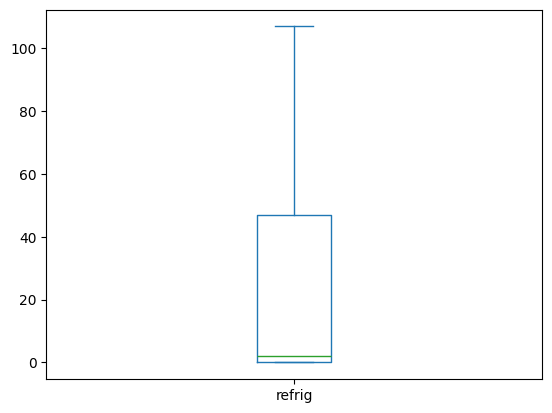

In [785]:
df_util_carga["refrig"].plot.box()

In [786]:
#df_util_carga["otros"].describe()

Valores de la columna otros en registros con estatus de carga llena dentro de los limites.


<Axes: >

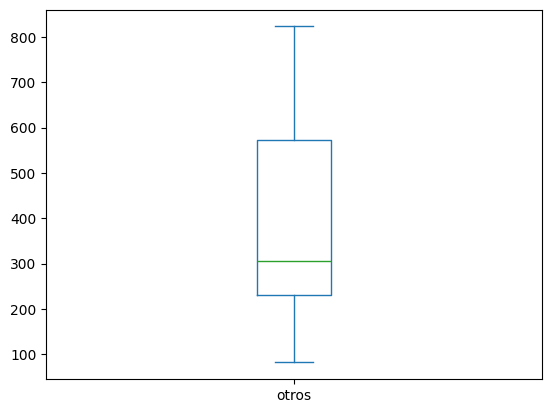

In [787]:
df_util_carga["otros"].plot.box()

**2.1.8 Agregar campos para análisis.**

In [788]:
df_util.shape    # filas y columnas equivalentes al 11.94% de registros reales

(204, 11)

In [789]:
# Estandarizar columnas
df_util['ll_vc'] = df_util['ll_vc'].str.strip().str.lower()
df_util['navegacion'] = df_util['navegacion'].str.strip().str.lower()
df_util['trafico'] = df_util['trafico'].str.strip().str.lower()
df_util['mes'] = df_util['mes'].str.strip().str.lower()

# Agregar columna tamanioContenedor como tipo entero
df_util['tamanioContenedor'] = (
    df_util['tamanio']
    .str.replace('pies', '', regex=False)
    .str.strip()
    .astype(int)
)

# Agregar columna fecha
meses_num = {
    'enero': 1, 'febrero': 2, 'marzo': 3, 'abril': 4,
    'mayo': 5, 'junio': 6, 'julio': 7, 'agosto': 8,
    'septiembre': 9, 'octubre': 10, 'noviembre': 11, 'diciembre': 12
}

# Agregar una columna con el número de mes
df_util['mes_num'] = df['mes'].map(meses_num)

# Convertir a fecha real usando una columna 'año' existente (y día 1 por defecto)
df_util['fecha'] = pd.to_datetime({
    'year': df_util['anio'],
    'month': df_util['mes_num'],
    'day': 1
})

df_util.shape    # filas y columnas

(204, 13)

In [790]:
df_util.head(5)

,ll_vc,navegacion,trafico,tamanio,refrig,otros,carga,tara,mes,anio,mes_num,tamanioContenedor,fecha
1,llenos,altura,importacion,20 pies,0.0,140.0,2982.104569,308.0,enero,2025,1,20,2025-01-01
2,llenos,altura,importacion,40 pies,107.0,728.0,17786.123681,3674.0,enero,2025,1,40,2025-01-01
6,llenos,altura,exportacion,20 pies,0.0,226.0,5468.814423,497.2,enero,2025,1,20,2025-01-01
7,llenos,altura,exportacion,40 pies,54.0,231.0,6896.513763,1254.0,enero,2025,1,40,2025-01-01
30,vacios,altura,importacion,10 pies,0.0,0.0,0.000000,0.0,enero,2025,1,10,2025-01-01


Agregar columna TEU (Twenty-foot Equivalent Unit) con base al tamaño del contenedor
[Equivalencia Contenedor - TEU](https://www.icontainers.com/es/2019/08/06/la-historia-del-teu-twenty-foot-equivalent-unit/)

In [791]:
# Función para asignar el equivalente en TEUs con base al tamaño del contenedor
def calcular_teus(tamanio):
    if tamanio == 10:
        return 0.5
    elif tamanio == 20:
        return 1.0
    elif tamanio >= 40 and tamanio <= 45:
        return 2.0
    elif tamanio == 53:
        return 2.5
    else:
        return 0.0

df_util['TEUs'] = df_util['tamanioContenedor'].apply(calcular_teus)
df_util.shape    # filas y columnas

(204, 14)

In [792]:
#df_util.head(5)

**3. IDENTIFICAR PATRONES**: *Usar estadísticas y visuales para observar tendencias y relaciones*:

In [793]:
df_analisis_tamanio = df_util.groupby(['fecha', 'mes','tamanioContenedor','trafico','navegacion','ll_vc'])['TEUs'].sum().reset_index().sort_values(by=['fecha','tamanioContenedor','navegacion','ll_vc'], ascending=True)
df_analisis_tamanio.shape    # filas y columnas

(204, 7)

In [794]:
#df_analisis_tamanio.head(5)

In [795]:
resumenMensual_trafico = df_analisis_tamanio.groupby(['fecha','mes','trafico','navegacion','ll_vc']).agg(
    TEUs_total=('TEUs', 'sum')
).reset_index().sort_values(by=['fecha','trafico'], ascending=True)
resumenMensual_trafico.shape    # filas y columnas

(48, 6)

In [796]:
#resumenMensual_trafico.head(5)

In [797]:
resumenGral_trafico = df_analisis_tamanio.groupby(['trafico','ll_vc']).agg(
    TEUs_total=('TEUs', 'sum')
).reset_index().sort_values(by='trafico', ascending=True)
resumenGral_trafico.shape    # filas y columnas

(6, 3)

In [798]:
#resumenGral_trafico.head(6)

In [799]:
resumenMedidas_trafico = df_analisis_tamanio.groupby(['trafico','ll_vc']).agg(
    TEUs_totales=('TEUs', 'sum'),
    TEUs_promedio=('TEUs', 'mean')
).reset_index().sort_values(by='trafico', ascending=False)
resumenMedidas_trafico.shape    # filas y columnas

(6, 4)

In [800]:
#resumenMedidas_trafico.head(6)

**4. COMUNICAR INSIGHTS**: *Documentar hallazgos, evidencias, próximas preguntas en un notebook*

**4.1 TOTAL DE CONTENEDORES POR MES Y ESTATUS DE CARGA**

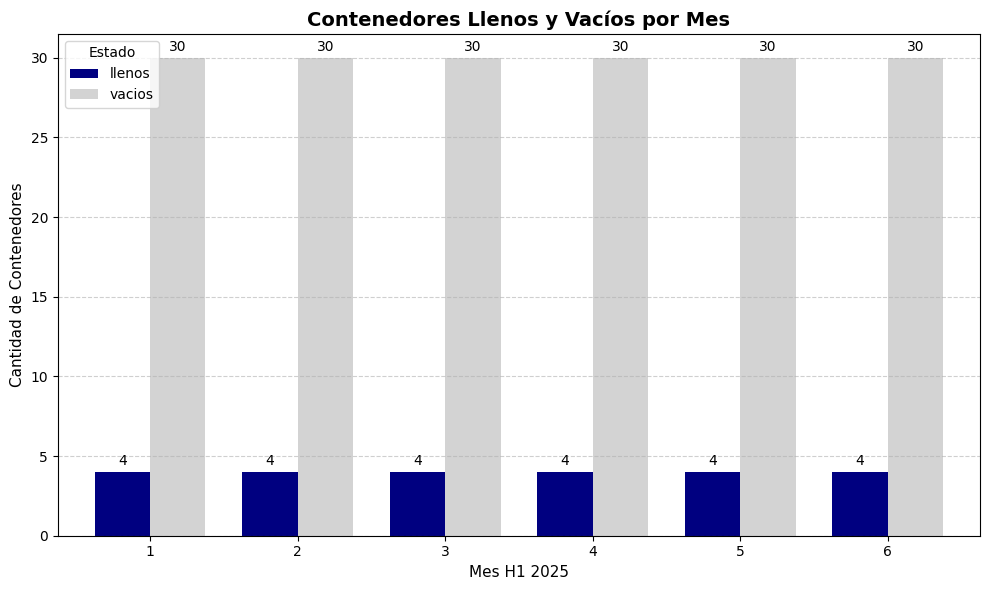

In [801]:
# 1. Agrupar por 'mes' y 'll_vc' para contar cuántos contenedores hay de cada tipo
resumen = df_util.groupby(['mes_num', 'll_vc']).size().unstack(fill_value=0).sort_values(by='mes_num', ascending=True)

# Renombrar las columnas si en 'll_vc' aparecen como 'LL' y 'VC'
resumen = resumen.rename(columns={'LL': 'Contenedores Llenos', 'VC': 'Contenedores Vacíos'})

# 2. Generar la gráfica de barras
# Azul para llenos, Gris para vacíos
ax = resumen.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#000080', '#D3D3D3'],
    width=0.75
)

# 3. Personalizar títulos y ejes
ax.set_title('Contenedores Llenos y Vacíos por Mes', fontsize=14, fontweight='bold')
ax.set_xlabel('Mes H1 2025', fontsize=11)
ax.set_ylabel('Cantidad de Contenedores', fontsize=11)

# Mantener los nombres o números de los meses horizontales
plt.xticks(rotation=0)
ax.legend(title='Estado')
ax.grid(axis='y', linestyle='--', alpha=0.6)

# 4. Agregar el número exacto encima de cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, padding=3)

plt.tight_layout()
plt.show()

**INSIGHTS 1: El puerto presenta una proporción mayor de contenedores vacíos que llenos, lo cual indica una subutilización de su capacidad instalada. Se sugiere ejecutar acciones estratégicas para fomentar la importación, la exportación y el movimiento de carga.**

**4.2 TOTAL DE TEUs POR MES**

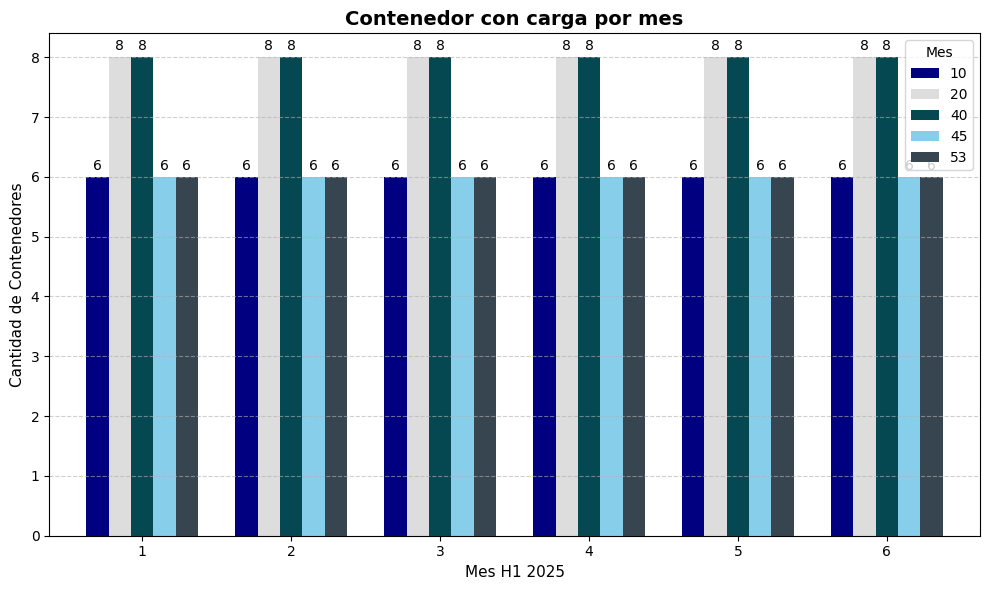

In [802]:
# 1. Agrupar por 'mes' y 'll_vc' para contar cuántos contenedores hay de cada tipo
resumen = df_util.groupby(['mes_num', 'tamanioContenedor']).size().unstack(fill_value=0).sort_values(by='mes_num', ascending=True)

# 2. Generar la gráfica de barras
ax = resumen.plot(
    kind='bar',
    figsize=(10, 6),
    color=['#000080', '#DDDDDD', '#054852','#87CEEB','#36454f'],
    width=0.75
)

# 3. Personalizar títulos y ejes
ax.set_title('Contenedor con carga por mes', fontsize=14, fontweight='bold')
ax.set_xlabel('Mes H1 2025', fontsize=11)
ax.set_ylabel('Cantidad de Contenedores', fontsize=11)

# Mantener los nombres o números de los meses horizontales
plt.xticks(rotation=0)
ax.legend(title='Mes')
ax.grid(axis='y', linestyle='--', alpha=0.6)

# 4. Agregar el número exacto encima de cada barra
for contenedor in ax.containers:
    ax.bar_label(contenedor, padding=3)

plt.tight_layout()
plt.show()

**INSIGHTS 2: El puerto presenta una translado mayor de TEUs de 20 y 40 pies, lo cual indica una subutilización de su capacidad instalada. Se sugiere implementar acciones que aumenten el cabotaje y transbordo de mercancías para emplear los TEUs de 10 pies y acciones que aumenten el maximo de la carga actual en exportación e importación para optimizar el empleo de contenedores de 45 y 53 pies.**

**4.3 TOTAL DE CARGA TRANSPORTADA POR MES**



In [803]:


condicion = (df_util['carga'] > 0.000000)
dfresumenCargaMes = df_util[condicion].groupby(['mes_num', 'carga','tamanioContenedor','navegacion', 'trafico']).size().copy().reset_index().sort_values(by='mes_num', ascending=True)
dfresumenCargaMes.shape
dfresumenCargaMes.head(5)



,mes_num,carga,tamanioContenedor,navegacion,trafico,0
0,1,2982.104569,20,altura,importacion,1
1,1,5468.814423,20,altura,exportacion,1
2,1,6896.513763,40,altura,exportacion,1
3,1,17786.123681,40,altura,importacion,1
4,2,1708.986685,20,altura,importacion,1


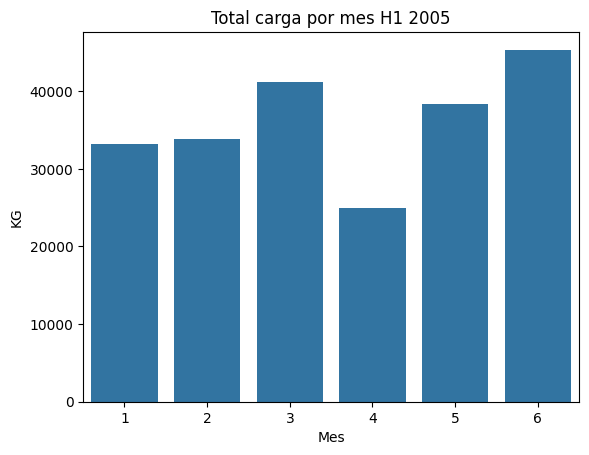

In [804]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Crear el gráfico de barras
sns.barplot(data=dfresumenCargaMes, x="mes_num", y="carga", estimator=sum, errorbar=None)

# 2. Personalizar títulos y mostrar
plt.title("Total carga por mes H1 2005")
plt.xlabel("Mes")
plt.ylabel("KG")
plt.show()

**INSIGHTS 3: El total de carga transportada en el puerto muestra una disminución en el mes de abril de 2025 lo cual indica una disminución de la demanda de transporte maritimo. Se sugiere implementar acciones de evaluación de riesgos para evitar esta disminución y mantener un crecimiento sostenido de la demanda.**

**4.4 TOTAL DE CARGA TRANSPORTADA POR MES**

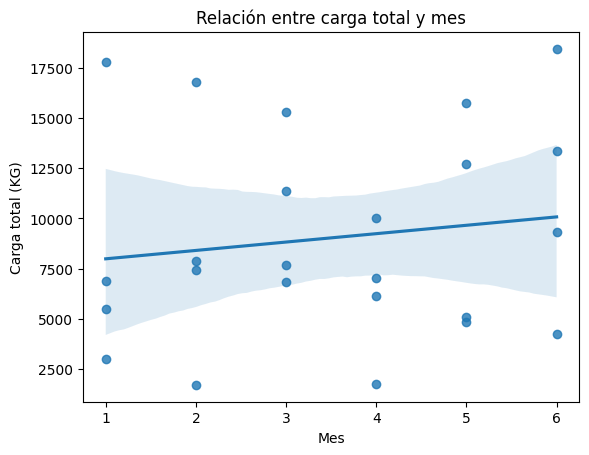

In [805]:
import seaborn as sns
import matplotlib.pyplot as plt



# 1. Crear gráfico de dispersión con línea de regresión
sns.regplot(data=dfresumenCargaMes, x="mes_num", y="carga")

# 2. Personalizar títulos y mostrar
plt.title("Relación entre carga total y mes")
plt.xlabel("Mes")
plt.ylabel("Carga total (KG)")
plt.show()

**INSIGHTS 4: Se presenta una ligera tendencia al alza en la carga total transportada en el puerto, se observa la dispersion debido al empleo de los contenedores de 20 y 40 pies para la importación y exportación.**

**4.5 TOTAL DE CARGA TRANSPORTADA POR MES, NAVEGACIÓN Y TRÁFICO**

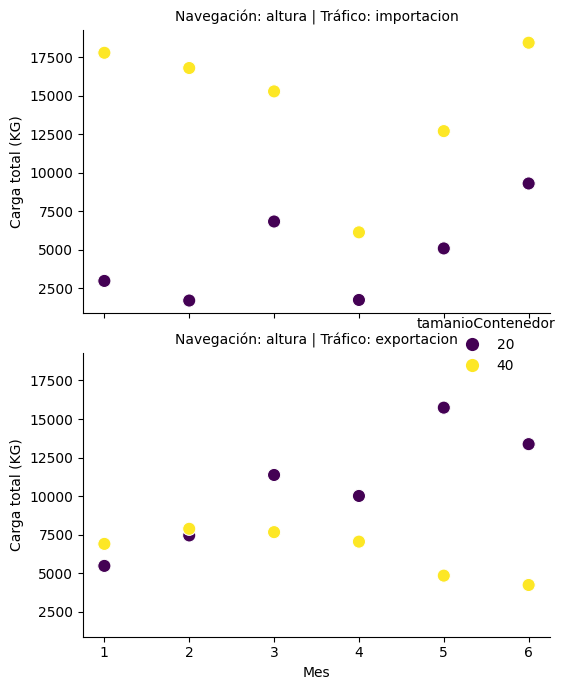

In [806]:
import seaborn as sns
import matplotlib.pyplot as plt

grafica = sns.relplot(
    data=dfresumenCargaMes,
    x='mes_num',
    y='carga',
    hue='tamanioContenedor',      # Color por tamaño (10, 20, 40, 45, 53)
    col='navegacion',       # Columnas: altura, cabotaje, traslado
    row='trafico',          # Filas: importacion, exportacion, salida, entrada
    kind='scatter',
    palette='viridis',
    s=90,
    height=3.5,
    aspect=1.2
)

grafica.set_axis_labels('Mes', 'Carga total (KG)')
grafica.set_titles('Navegación: {col_name} | Tráfico: {row_name}')
plt.tight_layout()
plt.show()

**INSIGHTS 5: La operación del puerto se concentra mayormente en la importación frente a la exportación, utilizando sobre todo contenedores de 20 y 40 pies y subutilizando los contenedores de 10, 45 y 53 pies. Se recomienda diseñar incentivos operativos y tarifas preferenciales para promover el uso de estos contenedores para optimizar la capacidad instalada a través del Sistema Nacional Portuario Mazatlán**

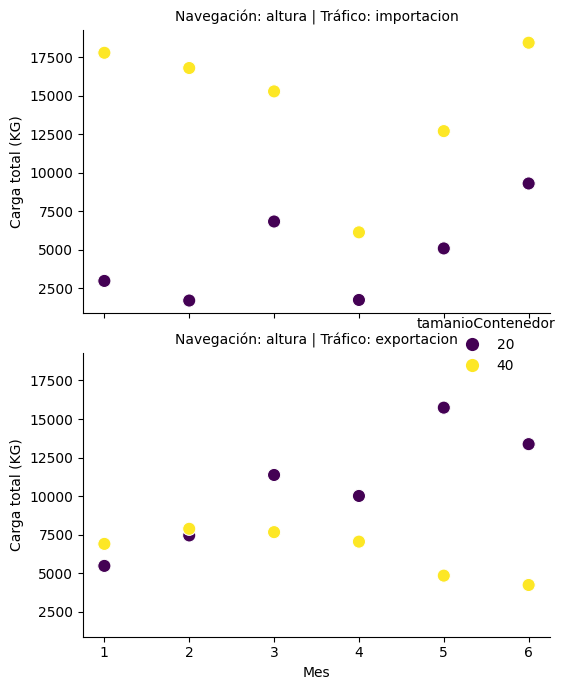

In [807]:
import seaborn as sns
import matplotlib.pyplot as plt

grafica = sns.relplot(
    data=dfresumenCargaMes,
    x='mes_num',
    y='carga',
    hue='tamanioContenedor',      # Color por tamaño (10, 20, 40, 45, 53)
    col='navegacion',       # Columnas: altura, cabotaje, traslado
    row='trafico',          # Filas: importacion, exportacion, salida, entrada
    kind='scatter',
    palette='viridis',
    s=90,
    height=3.5,
    aspect=1.2
)

grafica.set_axis_labels('Mes', 'Carga total (KG)')
grafica.set_titles('Navegación: {col_name} | Tráfico: {row_name}')
plt.tight_layout()
plt.show()

**/////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////**

**INSIGHTS 5: La operación del puerto se concentra mayormente en la importación frente a la exportación, utilizando sobre todo contenedores de 20 y 40 pies y subutilizando los contenedores de 10, 45 y 53 pies. Se recomienda diseñar incentivos operativos y tarifas preferenciales para promover el uso de estos contenedores para optimizar la capacidad instalada a través del Sistema Nacional Portuario Mazatlán**

**/////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////////**